# Event-related pupil dilations

We are often interested in how the pupil responds to certain events, for example stimuli. One method to investigate this is to extract the average pupil dilation surrounding the events of interest (event-related pupil dilation, ERPD).

In `pypillometry`, this works in two steps:

1. `get_intervals()` selects the events and defines a time window around each of them
2. `get_segments()` cuts the data in these windows into a `SegmentedEyeData` object that can be baseline-corrected, plotted and averaged

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt
import numpy as np

Here, we use the EDF file from the [import](importdata_edf.ipynb) examples, which is stored in the `data` folder of the repository.

pp: 12:52:42 | INFO     | _read_edf:628 | Loading EDF file: ../../data/test.edf (current log level: INFO, set to DEBUG to see eyelinkio output)


pp: 12:53:00 | INFO     | from_eyelink:1292 | Filtering out Eyelink triggers


EyeData(test.edf, 124.5MiB):
 n                 : 1245363
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 1027
 experimental_setup: {'screen_resolution': (np.int64(1920), np.int64(1080)), 'physical_screen_size_mm': None, 'eye_to_screen_distance_mm': 'not set', 'camera_position': 'not set'}
 calibration       : {'left': {'n': 9, 'mean': 0.9833333333333333, 'sd': 0.32605384695033296, 'max': 1.62, 'min': 0.49}, 'right': {'n': 9, 'mean': 0.4955555555555555, 'sd': 0.27427120038025266, 'max': 0.91, 'min': 0.15}}
 duration_minutes  : 41.512100000000004
 start_min         : 0.0
 end_min           : 41.51206666666667
 parameters        : {}
 glimpse           : EyeDataDict(vars=6,n=1245363,shape=(1245363,)): 
  left_x (float64): 817.2999877929688, 817.0, 816.7000122070312, 816.7000122070312, 816.7000122070312...
  left_y (float64): 345.20001220703125, 343.5, 341.6000061035156, 340.3999938964844, 340.20001220703125...
  left_pupil (float64): 1707.0, 1706.0, 1705.0, 1706.0, 1707.0...
  right_x (float64): 860.5999755859375, 860.7000122070312, 861.2000122070312, 861.7000122070312, 861.5999755859375...
  right_y (float64): 375.20001220703125, 375.8999938964844, 376.6000061035156, 376.79998779296875, 376.8999938964844...
  right_pupil (float64): 1738.0, 1739.0, 1739.0, 1740.0, 1742.0...

 nblinks           : {}
 blinks            : {'left': None, 'right': None}
 params            : {}
 Info: 1 keys: eyelink_info
 History:
 *
 └ fill_time_discontinuities()
  └ set_events(Events(1027))
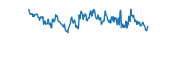
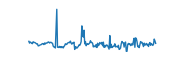
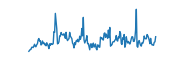
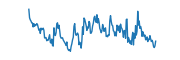
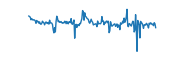
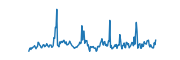

In [2]:
d = pp.EyeData.from_eyelink("../../data/test.edf")
d

Next, we apply a basic blink detection and interpolation pipeline as illustrated in the [blinks](blinks.ipynb) example, followed by a low-pass filter and z-scaling:

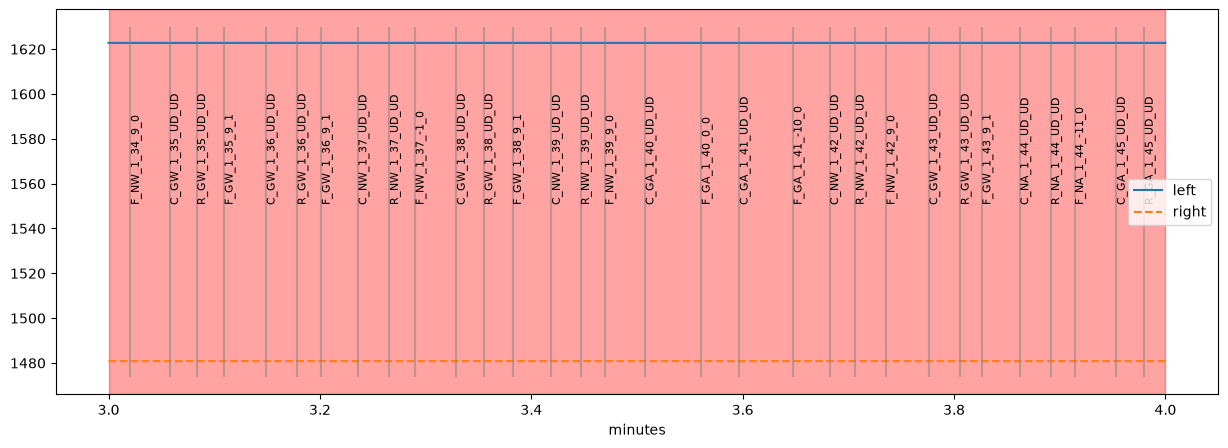

In [3]:
d.pupil_blinks_detect(vel_onset=-15, apply_mask=True)\
 .blinks_merge_close(distance=100 * u.ms, apply_mask=True)\
 .pupil_blinks_interpolate(margin=(50, 150) * u.ms)\
 .pupil_lowpass_filter(cutoff=5)\
 .scale(variables="pupil")

plt.figure(figsize=(15, 5))
d.plot.pupil_plot(plot_range=(3, 4) * u.min, units="min")

Next, we want to create ERPDs based on some of the event markers in this dataset. The markers have a special structure where each label contains information about the stimulus, the experimental condition, the block etc. Let's look at the first few events:

In [4]:
list(d.event_labels[0:5])

[np.str_('DISPLAY_COORDS = 0 0 1919 1079'),
 np.str_('experiment_start'),
 np.str_('C_GW_1_1_UD_UD'),
 np.str_('F_GW_1_1_10_0'),
 np.str_('C_NW_1_2_UD_UD')]

The first letter codes which stimulus was presented, the letters after the first underscore code the experimental condition. We use `get_intervals()` to select the events and the time window around them. We start by extracting all stimuli coded as "C" (cues) by using `event_select="C_"`, which matches all labels that contain the string "C_". The window goes from 500 ms before until 2000 ms after each cue:

In [5]:
cue_intervals = d.get_intervals("C_", interval=(-500, 2000) * u.ms)
cue_intervals

Intervals 'C_' | 400 intervals (total duration: 1000000.00 ms), 2500.00 ms +/- 0.00 ms, [2500.00 ms, 2500.00 ms] | fs=500.0Hz

`get_segments()` extracts the data in these intervals for one variable (here, the pupil of the left eye). We then apply a baseline correction by subtracting the mean in the 200 ms before the cue (the baseline window is given in ms):

pp: 12:53:05 | INFO     | baseline_correct:448 | Baseline correction applied using window (-200, 0)


SegmentedEyeData(cue):
  variable      : left_pupil
  n_segments    : 400
  n_timepoints  : 1250
  window        : (np.float64(-500.0), np.float64(2000.0))
  percent_masked: 99.57
  sampling_rate : 500.00
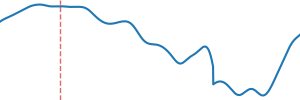

In [6]:
erpd_cue = d.get_segments(cue_intervals, "left_pupil", name="cue")\
            .baseline_correct(window=(-200, 0))
erpd_cue

This ERPD contains one segment per cue, from 500 ms before until 2000 ms after the cue onset. The `plot()` function shows the mean curve and its standard error. In addition, it shows the percentage of missing (masked, e.g., interpolated) datapoints at each time point. We can choose what is displayed as the error ribbon by passing a function to `varfct`. For example, we can use `varfct=np.std` to display the standard deviation instead of the standard error.

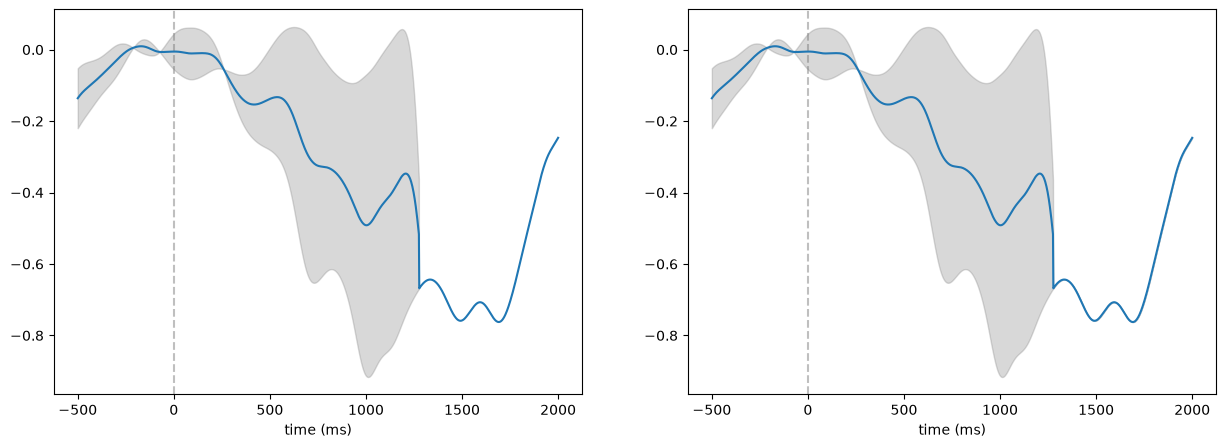

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
erpd_cue.plot(ax=axs[0], title="standard error")
erpd_cue.plot(varfct=np.std, ax=axs[1], title="standard deviation");

Sometimes, selecting events based on a string is not sufficient. For example, in our dataset, we would like to compare cues (labels starting with "C_") from conditions "GW" and "NA" against cues from conditions "NW" and "GA" (what exactly that means is not important here). We can do that by passing a function as `event_select`. The function should return `True` whenever a label should be used and `False` otherwise. Here are two such functions, one for cues from the "GW"/"NA" conditions (call them "congruent") and one for the "NW"/"GA" conditions (call them "conflict"):

In [8]:
def is_conflict_cue(label):
    parts = label.split("_")
    return len(parts) >= 2 and parts[0] == "C" and parts[1] in ["NW", "GA"]

def is_congruent_cue(label):
    parts = label.split("_")
    return len(parts) >= 2 and parts[0] == "C" and parts[1] in ["GW", "NA"]

First, the label is split into parts at "_". The functions return `True` only if the first part is a "C" and the second part is one of the relevant conditions. We can check that the functions work by applying them to some labels:

In [9]:
is_congruent_cue("C_GW"), is_congruent_cue("C_GA")

(True, False)

`test_selector()` shows which of the events in the dataset are selected by such a function:

In [10]:
from pypillometry.convenience import test_selector
test_selector(d, is_conflict_cue)

array(['C_NW_1_2_UD_UD', 'C_GA_1_4_UD_UD', 'C_GA_1_5_UD_UD',
       'C_GA_1_8_UD_UD', 'C_NW_1_10_UD_UD', 'C_GA_1_12_UD_UD',
       'C_NW_1_14_UD_UD', 'C_GA_1_17_UD_UD', 'C_GA_1_18_UD_UD',
       'C_NW_1_20_UD_UD', 'C_NW_1_25_UD_UD', 'C_GA_1_27_UD_UD',
       'C_GA_1_28_UD_UD', 'C_NW_1_29_UD_UD', 'C_GA_1_30_UD_UD',
       'C_NW_1_32_UD_UD', 'C_NW_1_34_UD_UD', 'C_NW_1_37_UD_UD',
       'C_NW_1_39_UD_UD', 'C_GA_1_40_UD_UD', 'C_GA_1_41_UD_UD',
       'C_NW_1_42_UD_UD', 'C_GA_1_45_UD_UD', 'C_NW_1_47_UD_UD',
       'C_NW_1_50_UD_UD', 'C_NW_1_52_UD_UD', 'C_GA_1_54_UD_UD',
       'C_NW_1_55_UD_UD', 'C_GA_1_57_UD_UD', 'C_NW_1_59_UD_UD',
       'C_GA_1_64_UD_UD', 'C_NW_1_66_UD_UD', 'C_GA_1_67_UD_UD',
       'C_GA_1_70_UD_UD', 'C_GA_1_72_UD_UD', 'C_GA_1_73_UD_UD',
       'C_NW_1_75_UD_UD', 'C_NW_1_76_UD_UD', 'C_GA_1_77_UD_UD',
       'C_NW_1_79_UD_UD', 'C_GA_2_3_UD_UD', 'C_GA_2_6_UD_UD',
       'C_NW_2_9_UD_UD', 'C_GA_2_10_UD_UD', 'C_NW_2_11_UD_UD',
       'C_NW_2_13_UD_UD', 'C_GA_2_14_UD_UD', 'C

Now we can create one ERPD for each of the selection functions:

In [11]:
erpd_conf = d.get_segments(d.get_intervals(is_conflict_cue, interval=(-500, 2000) * u.ms),
                           "left_pupil", name="conflict").baseline_correct(window=(-200, 0))
erpd_cong = d.get_segments(d.get_intervals(is_congruent_cue, interval=(-500, 2000) * u.ms),
                           "left_pupil", name="congruent").baseline_correct(window=(-200, 0))

pp: 12:53:06 | INFO     | baseline_correct:448 | Baseline correction applied using window (-200, 0)


pp: 12:53:07 | INFO     | baseline_correct:448 | Baseline correction applied using window (-200, 0)


Finally, we plot both into the same axes to compare them:

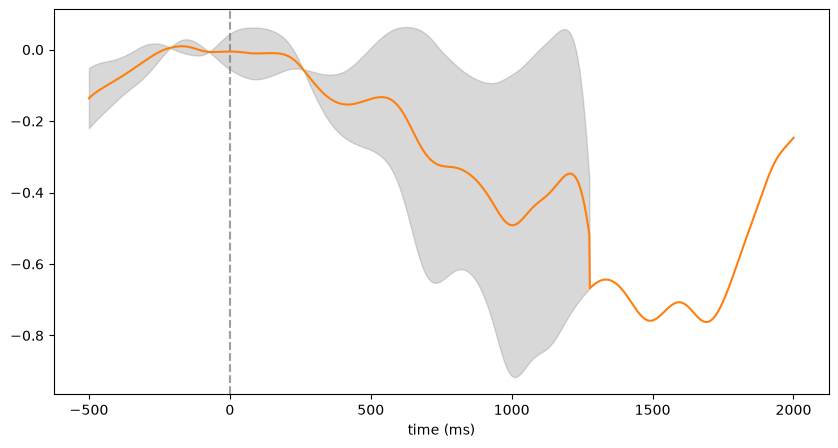

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
erpd_conf.plot(ax=ax, label="conflict")
erpd_cong.plot(ax=ax, label="congruent", title="Cues");

## Group-level ERPDs

With data from several subjects, `pp.group_segments()` averages the ERPDs of each subject (here, we use the two conditions as a stand-in for two subjects). The result is a `GroupLevelSegmentedData` object which can be plotted in the same way:

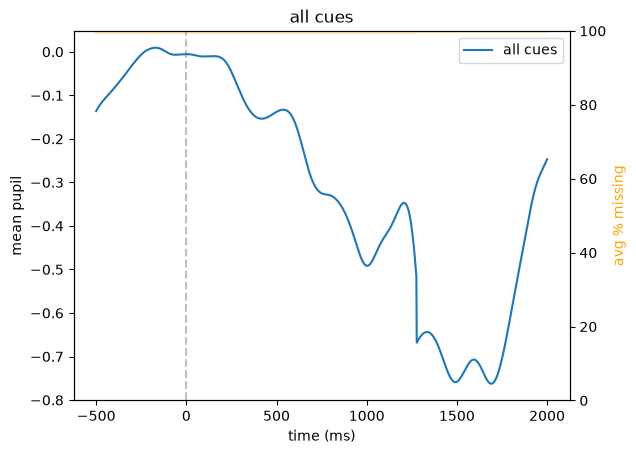

In [13]:
group = pp.group_segments([erpd_conf, erpd_cong], name="all cues")
group.plot();